**Bayes' and kNN classifier from scratch**

Images of forest and urban landscapes - Loading and preparing data

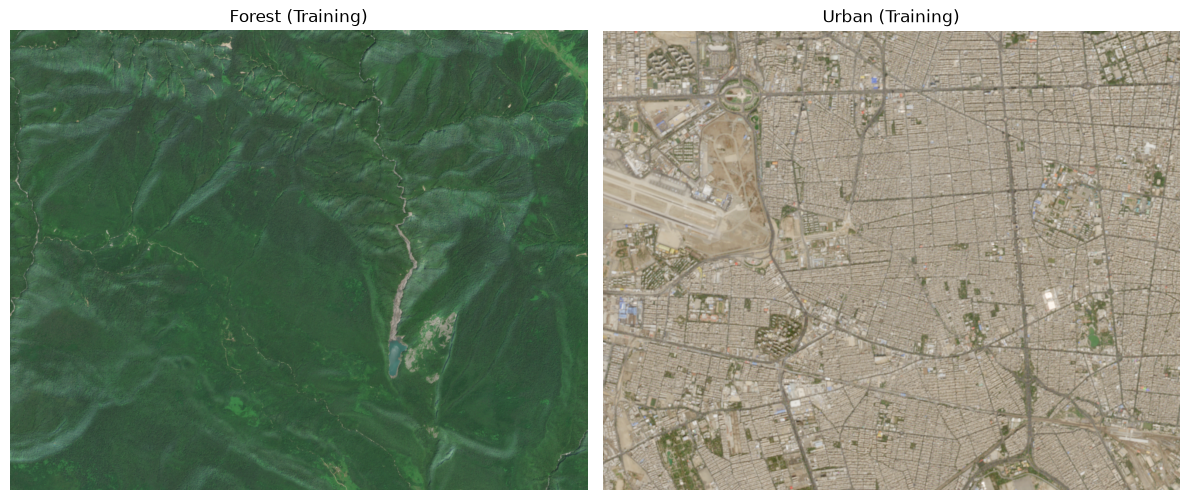

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import norm

forest_img = np.array(Image.open('D:/agh/Machine-Learing/2026-07-25-00_00_2026-07-25-23_59_Sentinel-2_L2A_True_color.tiff'))[:, :, :3] / 255.0
urban_img = np.array(Image.open('D:/agh/Machine-Learing/2026-10-13-00_00_2026-10-13-23_59_Sentinel-2_L2A_True_color.tiff'))[:, :, :3] / 255.0

fig_input, axes_input = plt.subplots(1, 2, figsize=(12, 8))
axes_input[0].imshow(forest_img)
axes_input[0].set_title('Forest (Training)')
axes_input[1].imshow(urban_img)
axes_input[1].set_title('Urban (Training)')

for ax in axes_input:
    ax.axis('off')

plt.tight_layout()
plt.show()

Histograms of the images - Determination of distribution parameters

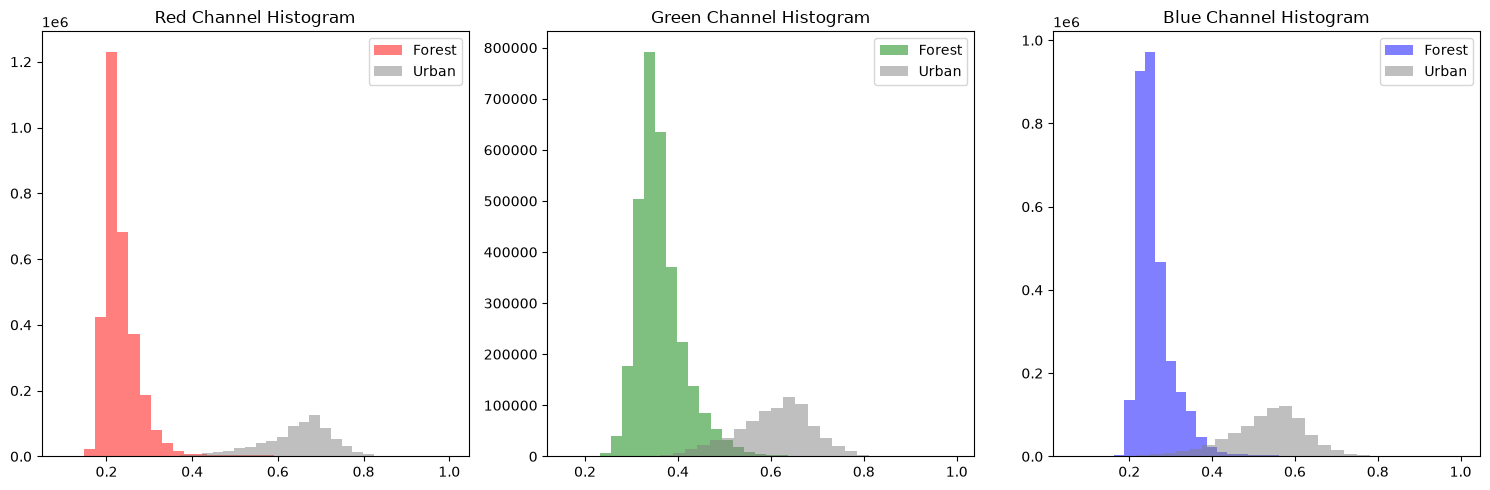

In [30]:
f_pixels = forest_img.reshape(-1, 3)
u_pixels = urban_img.reshape(-1, 3)

f_mean = np.mean(f_pixels, axis=0)
f_cov = np.cov(f_pixels, rowvar=False)

u_mean = np.mean(u_pixels, axis=0)
u_cov = np.cov(u_pixels, rowvar=False)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for c_idx, color in enumerate(['Red', 'Green', 'Blue']):
    axes[c_idx].hist(f_pixels[:, c_idx], bins=30, alpha=0.5, color=color.lower(), label='Forest')
    axes[c_idx].hist(u_pixels[:, c_idx], bins=30, alpha=0.5, color='gray', label='Urban')
    axes[c_idx].set_title(f'{color} Channel Histogram')
    axes[c_idx].legend()
plt.tight_layout()
plt.show()

New image - Loading data

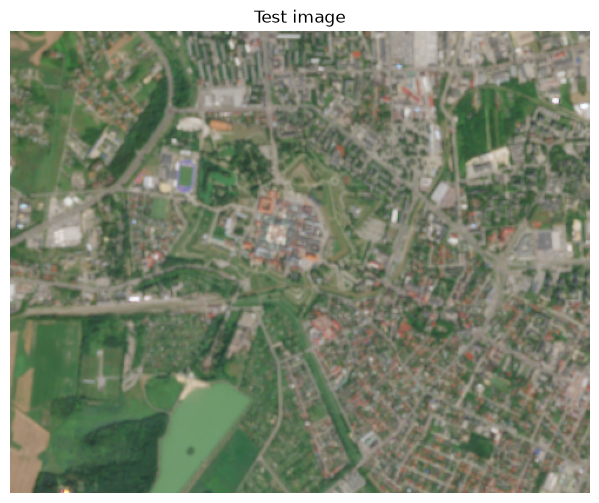

In [29]:
test_img = np.array(Image.open('D:/agh/Machine-Learing/2026-08-06-00_00_2026-08-06-23_59_Sentinel-2_L2A_True_color.tiff'))[:, :, :3] / 255.0

plt.figure(figsize=(9,6))
plt.axis('off')
plt.title('Test image')
plt.imshow(test_img, cmap='gray')

**Bayes classifier** and probability density pattern


blue - urban

red - forest

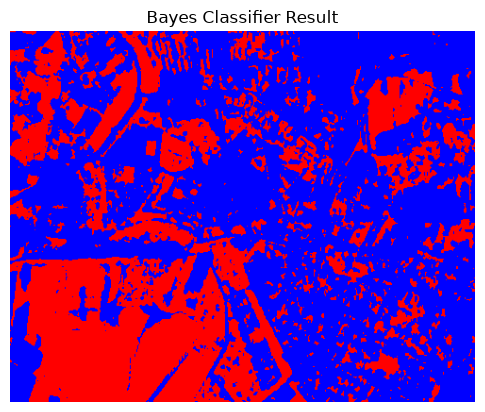

In [31]:
def gaussian_pdf(x, mean, cov):
    d = len(mean)
    det = np.linalg.det(cov)
    inv = np.linalg.inv(cov)
    norm_const = 1.0 / (np.power(2 * np.pi, d / 2) * np.sqrt(det))
    x_m = x - mean
    return norm_const * np.exp(-0.5 * np.sum((x_m @ inv) * x_m, axis=1))

def predict_bayes(img, f_m, f_c, u_m, u_c):
    h, w, c = img.shape
    pixels = img.reshape(-1, 3)
    p_forest = gaussian_pdf(pixels, f_m, f_c)
    p_urban = gaussian_pdf(pixels, u_m, u_c)
    labels = (p_urban > p_forest).astype(int)
    
    output = np.zeros((h * w, 3))
    output[labels == 0] = [1, 0, 0]
    output[labels == 1] = [0, 0, 1]
    return output.reshape(h, w, 3)

bayes_result = predict_bayes(test_img, f_mean, f_cov, u_mean, u_cov)

plt.figure(figsize=(6, 6))
plt.imshow(bayes_result)
plt.title('Bayes Classifier Result')
plt.axis('off')
plt.show()

**kNN classifier**

blue - urban

red - forest

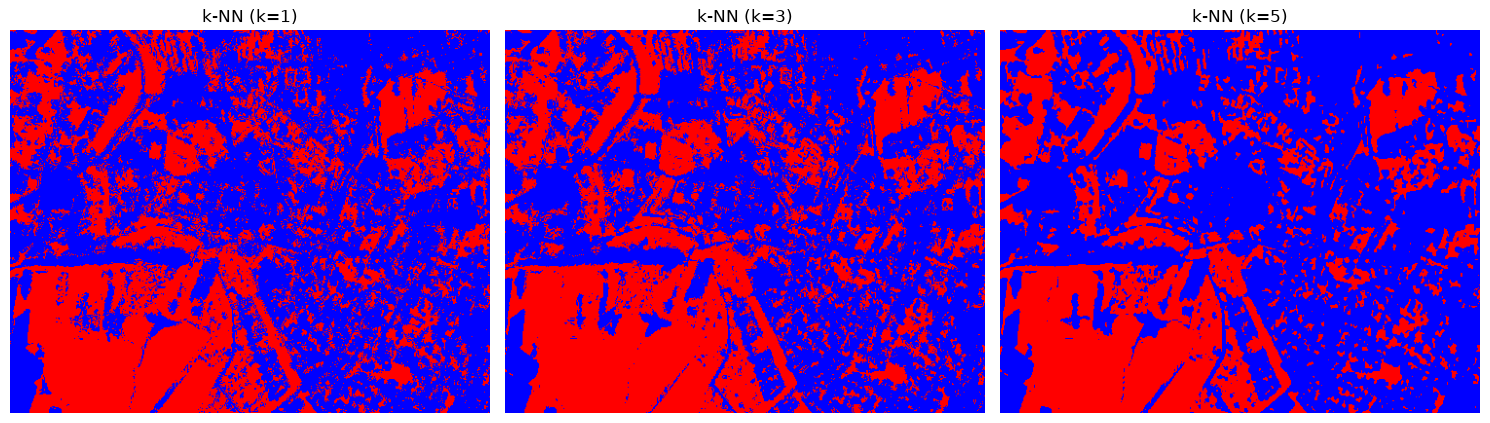

In [32]:
def predict_knn(test_img, train_f, train_u, k):
    h, w, c = test_img.shape
    test_pixels = test_img.reshape(-1, 3)
    
    n_samples = 1000
    idx_f = np.random.choice(len(train_f), n_samples, replace=False)
    idx_u = np.random.choice(len(train_u), n_samples, replace=False)
    
    X_train = np.vstack([train_f[idx_f], train_u[idx_u]])
    y_train = np.array([0] * n_samples + [1] * n_samples)
    
    output = np.zeros((h * w, 3))
    for i, p in enumerate(test_pixels):
        dists = np.sqrt(np.sum((X_train - p) ** 2, axis=1))
        k_indices = np.argsort(dists)[:k]
        k_labels = y_train[k_indices]
        label = 1 if np.sum(k_labels) > k / 2 else 0
        output[i] = [0, 0, 1] if label == 1 else [1, 0, 0]
        
    return output.reshape(h, w, 3)

knn_k1 = predict_knn(test_img, f_pixels, u_pixels, k=1)
knn_k3 = predict_knn(test_img, f_pixels, u_pixels, k=3)
knn_k5 = predict_knn(test_img, f_pixels, u_pixels, k=5)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(knn_k1)
axes[0].set_title('k-NN (k=1)')
axes[1].imshow(knn_k3)
axes[1].set_title('k-NN (k=3)')
axes[2].imshow(knn_k5)
axes[2].set_title('k-NN (k=5)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Observations:**

The parametric Bayes classifier effectively separates regions based on the global distribution of color channels. The classification boundary smooths out minor noise due to the quadratic decision boundary formed by multivariate Gaussians.

For lower k the decision boundary is highly sensitive to noise and outliers present in the pixel values. Higher k increases spatial smoothing, producing broader continuous regions of red and blue. However, ultra-fine visual details at the edges of urban structures may become slightly blunted compared to lower values of k.